# ClockMesh — three-DOT full plotting

Notebook equivalent of `ClockMeshTest.plot_observations`, with an additional **three-sensor motion magnitude comparison** and an optional zoom window. It reads a saved `observations.csv`; no hardware, ClockMesh library or tooling module import is required.

**Timeline convention:** the origin is the first gateway callback timestamp in the CSV. The clock-model diagnostics use **gateway callback time** on the horizontal axis; all motion traces use **`mapped_timestamp_ns`** on the horizontal axis. Every DOT shares the same origin. **No sensor trace is shifted, cross-correlated or interpolated.**

Run the configuration and loading cells first, then the plotting cells. Set `MOTION_ZOOM = (10, 15)` to inspect a five-second interval (seconds since first captured gateway callback).

In [7]:
%matplotlib inline
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Use the existing test capture. If the notebook is elsewhere, change SOURCE.
#SOURCE = Path("../output-files/clock-mesh/20261113T075728.451379Z_4d012a4f/observations.csv")
SOURCE = Path("../output-files/clock-mesh/20261113T082150.689022Z_0430302f/observations.csv")

BIN_SECONDS = 1.0
MOTION_PHASE = "measurement"  # "measurement" or "all_mapped"
MOTION_ZOOM = None            # Example: (10, 15), seconds from first gateway callback
ACCEL_DISPLAY = "deviation"   # "deviation" (from per-DOT baseline) or "magnitude"

SHOW_DIAGNOSTICS = True
SHOW_MAGNITUDES = True
SHOW_INDIVIDUAL_CHANNELS = True
SAVE_PLOTS = False             # If True, save PNGs alongside the CSV in notebook-plots/

MOTION_CHANNELS = (
    ("quat_w", "quat_w", "dimensionless"),
    ("quat_x", "quat_x", "dimensionless"),
    ("quat_y", "quat_y", "dimensionless"),
    ("quat_z", "quat_z", "dimensionless"),
    ("accel_x_m_s2", "accel_x", "m/s²"),
    ("accel_y_m_s2", "accel_y", "m/s²"),
    ("accel_z_m_s2", "accel_z", "m/s²"),
    ("gyro_x_deg_s", "gyro_x", "deg/s"),
    ("gyro_y_deg_s", "gyro_y", "deg/s"),
    ("gyro_z_deg_s", "gyro_z", "deg/s"),
)

if not np.isfinite(BIN_SECONDS) or BIN_SECONDS <= 0:
    raise ValueError("BIN_SECONDS must be finite and positive")
if MOTION_PHASE not in {"measurement", "all_mapped"}:
    raise ValueError("MOTION_PHASE must be 'measurement' or 'all_mapped'")
if ACCEL_DISPLAY not in {"deviation", "magnitude"}:
    raise ValueError("ACCEL_DISPLAY must be 'deviation' or 'magnitude'")
if MOTION_ZOOM is not None and not (len(MOTION_ZOOM) == 2 and MOTION_ZOOM[0] < MOTION_ZOOM[1]):
    raise ValueError("MOTION_ZOOM must be None or (start, end) in seconds")


In [8]:
required = {
    "address", "sensor_id", "connection_epoch", "stream_phase",
    "reference_time_ns", "mapped_timestamp_ns", "estimated_scale_ns_per_source_unit"
}

with SOURCE.open(newline="", encoding="utf-8") as handle:
    reader = csv.DictReader(handle)
    columns = set(reader.fieldnames or [])
    missing = required - columns
    if missing:
        raise ValueError(f"Missing CSV columns: {sorted(missing)}")
    rows = list(reader)

if not rows:
    raise ValueError("Observations CSV is empty")
if not any(r["mapped_timestamp_ns"] for r in rows):
    raise ValueError("No mapped timestamps to plot")

# Integer subtraction before division avoids losing precision with large ns timestamps.
origin_ns = min(int(r["reference_time_ns"]) for r in rows)
end_s = max((int(r["reference_time_ns"]) - origin_ns) / 1e9 for r in rows)

groups = {}
for row in rows:
    key = (row["address"], row["sensor_id"], row["connection_epoch"])
    groups.setdefault(key, []).append(row)
keys = sorted(groups)
colors = plt.get_cmap("tab10")
color_for = {key: colors(i % 10) for i, key in enumerate(keys)}

def label_for(key):
    address, sensor_id, epoch = key
    return f"DOT {sensor_id} · {address[-5:]} · epoch {epoch}"

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

print(f"Source: {SOURCE.resolve()}")
print(f"CSV rows: {len(rows):,}; common gateway origin: {origin_ns} ns")
print(f"Captured gateway-reference span: {end_s:.3f} s")
for key in keys:
    samples = groups[key]
    measured = sum(r["stream_phase"] == "measurement" for r in samples)
    mapped = sum(bool(r["mapped_timestamp_ns"]) for r in samples)
    print(f"  {label_for(key)}: {len(samples):,} rows, {mapped:,} mapped, {measured:,} measurement")


Source: /home/mike/Desktop/apps/dev/rs-nexus-project/nexus-n3-ble-tooling/output-files/clock-mesh/20261113T082150.689022Z_0430302f/observations.csv
CSV rows: 5,354; common gateway origin: 1553963424000 ns
Captured gateway-reference span: 29.860 s
  DOT 0 · B4:43 · epoch 1: 1,792 rows, 1,731 mapped, 1,475 measurement
  DOT 2 · B4:5E · epoch 1: 1,777 rows, 1,716 mapped, 1,475 measurement
  DOT 1 · B8:3E · epoch 1: 1,785 rows, 1,724 mapped, 1,475 measurement


In [9]:
def gateway_seconds(device_rows):
    return np.array([(int(r["reference_time_ns"]) - origin_ns) / 1e9
                     for r in device_rows], dtype=float)


def mapped_seconds(device_rows):
    return np.array([(int(r["mapped_timestamp_ns"]) - origin_ns) / 1e9
                     for r in device_rows], dtype=float)


def numeric_column(device_rows, column):
    return np.array([float(r[column]) if r.get(column, "") else np.nan
                     for r in device_rows], dtype=float)


def mapped_rows_for(key, measurement_only=False):
    return [r for r in groups[key]
            if r["mapped_timestamp_ns"]
            and (not measurement_only or r["stream_phase"] == "measurement")]


def motion_rows_for(key):
    selected = mapped_rows_for(key, measurement_only=(MOTION_PHASE == "measurement"))
    # Sorting by mapped source time also protects the plot from interleaved arrivals.
    return sorted(selected, key=lambda r: int(r["mapped_timestamp_ns"]))


def motion_xyz(device_rows, family):
    return np.column_stack([
        numeric_column(device_rows, f"{family}_{axis}_{'deg_s' if family == 'gyro' else 'm_s2'}")
        for axis in 'xyz'
    ])


def finish_figure(fig, filename):
    if SAVE_PLOTS:
        target = SOURCE.parent / "notebook-plots" / filename
        target.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(target, dpi=180, bbox_inches="tight")
        print(f"Saved {target.resolve()}")
    plt.show()


def set_motion_xlim(axes):
    if MOTION_ZOOM is not None:
        for axis in np.atleast_1d(axes):
            axis.set_xlim(*MOTION_ZOOM)


## 1 — Clock and BLE timing diagnostics

These plots reproduce the three diagnostic panels in the existing CLI script. The residual is **gateway callback time minus the pre-update accepted mapping**; it contains BLE scheduling and callback effects, so it **is not** a physical-event synchronisation error. The residual summary below uses **official measurement only**. Dashed vertical markers indicate each sensor's first recorded acceptance (approximately the common official-start boundary).

DOT 0 · B4:43 · epoch 1: official residual mean +1.044 ms, population σ 8.411 ms (n=1475)
DOT 2 · B4:5E · epoch 1: official residual mean +1.217 ms, population σ 8.581 ms (n=1475)
DOT 1 · B8:3E · epoch 1: official residual mean +1.437 ms, population σ 8.431 ms (n=1475)


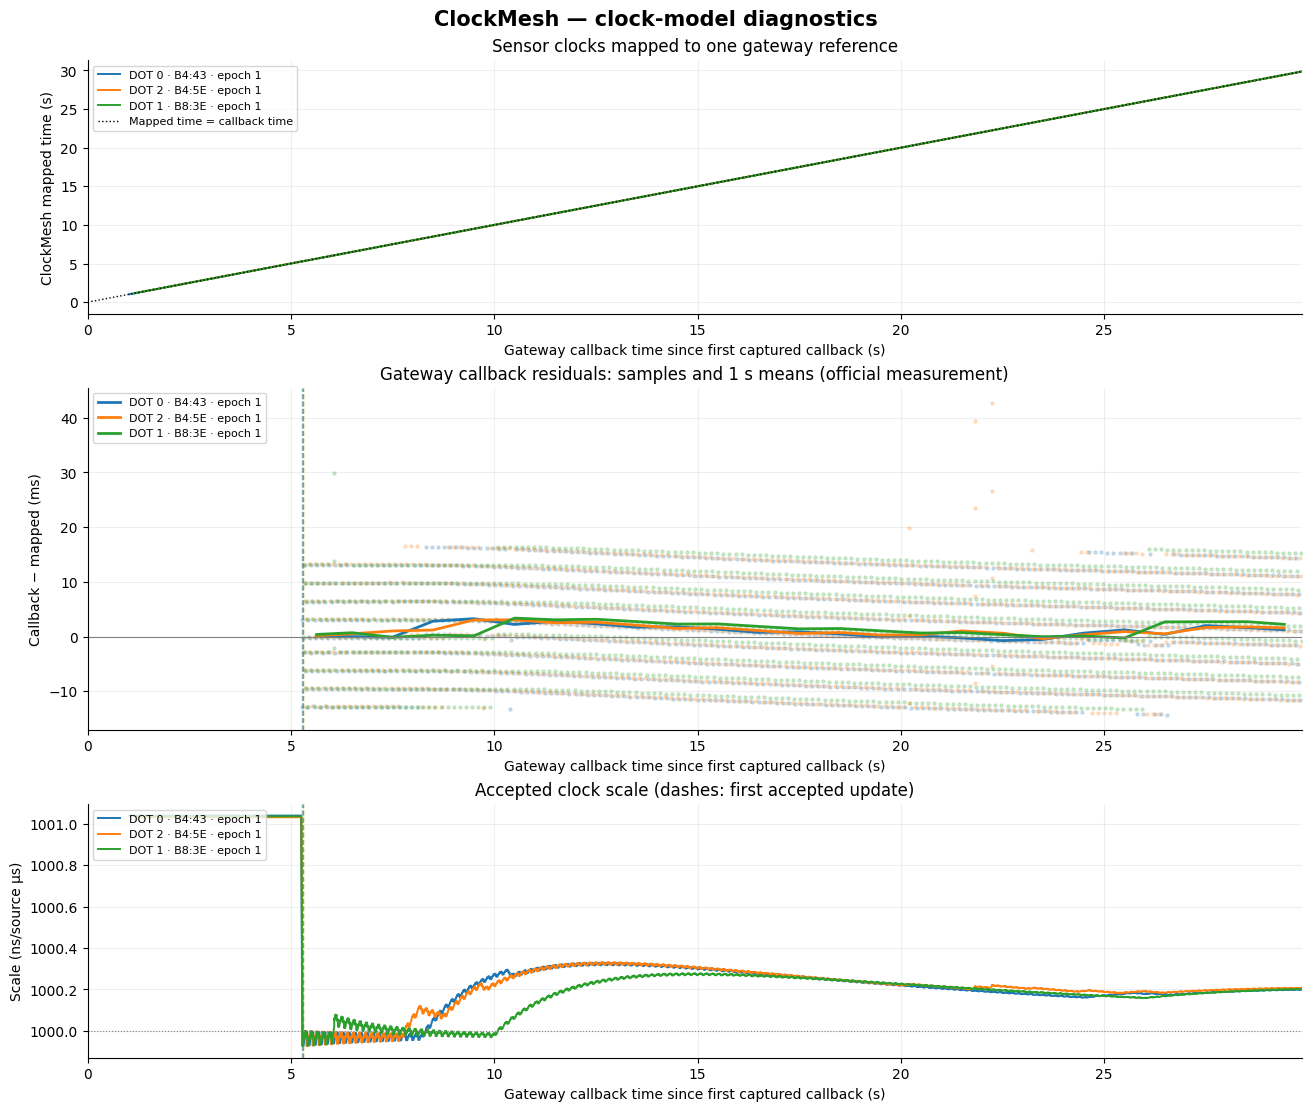

In [11]:
if SHOW_DIAGNOSTICS:
    fig, axes = plt.subplots(
        3, 1, figsize=(13, 11), layout="constrained",
        gridspec_kw={"height_ratios": [1.0, 1.35, 1.0]}
    )

    for key in keys:
        data = mapped_rows_for(key)
        official = mapped_rows_for(key, measurement_only=True)
        if not data:
            print(f"Skipping {label_for(key)}: no mapped timestamps")
            continue
        color = color_for[key]
        label = label_for(key)

        t_ref = gateway_seconds(data)
        t_mapped = mapped_seconds(data)
        axes[0].plot(t_ref, t_mapped, color=color, lw=1.4, label=label)

        if official:
            t_official = gateway_seconds(official)
            residual_ms = np.array([
                (int(r["reference_time_ns"]) - int(r["mapped_timestamp_ns"])) / 1e6
                for r in official
            ])
            axes[1].scatter(t_official, residual_ms, color=color, s=5, alpha=.20)

            bin_ids = np.floor(t_official / BIN_SECONDS).astype(int)
            centers = [float(t_official[bin_ids == k].mean()) for k in np.unique(bin_ids)]
            mean_residual = [float(residual_ms[bin_ids == k].mean()) for k in np.unique(bin_ids)]
            axes[1].plot(centers, mean_residual, color=color, lw=2, label=label)
            print(f"{label}: official residual mean {residual_ms.mean():+.3f} ms, "
                  f"population σ {residual_ms.std():.3f} ms (n={len(residual_ms)})")

        scale = numeric_column(data, "estimated_scale_ns_per_source_unit")
        axes[2].plot(t_ref, scale, color=color, lw=1.4, label=label)

        accepted = [r for r in data
                    if r.get("candidate_accepted", "").lower() in {"true", "1"}]
        if accepted:
            first_acceptance_s = (int(accepted[0]["reference_time_ns"]) - origin_ns) / 1e9
            for axis in axes[1:]:
                axis.axvline(first_acceptance_s, color=color, ls="--", alpha=.55, lw=1)

    axes[0].plot([0, end_s], [0, end_s], "k:", lw=1,
                 label="Mapped time = callback time")
    axes[0].set(title="Sensor clocks mapped to one gateway reference",
                ylabel="ClockMesh mapped time (s)")
    axes[1].axhline(0, color="grey", lw=.8)
    axes[1].set(title=f"Gateway callback residuals: samples and {BIN_SECONDS:g} s means (official measurement)",
                ylabel="Callback − mapped (ms)")
    axes[2].axhline(1000, color="grey", lw=.8, ls=":")
    axes[2].set(title="Accepted clock scale (dashes: first accepted update)",
                ylabel="Scale (ns/source µs)")
    for axis in axes:
        axis.set_xlim(0, max(end_s, 1))
        axis.grid(alpha=.20)
        axis.legend(loc="upper left", fontsize=8)
        axis.set_xlabel("Gateway callback time since first captured callback (s)")
    fig.suptitle("ClockMesh — clock-model diagnostics", fontsize=15, fontweight="bold")
    finish_figure(fig, "01_clock_diagnostics.png")


## 2 — Motion magnitudes on the common ClockMesh timeline

**This is the main alignment view.** All three DOTs are overlaid on the **same mapped time axis** (`mapped_timestamp_ns`), without time shifts.

- **Angular speed:** `sqrt(gyro_x² + gyro_y² + gyro_z²)` in degrees/second. Unlike an individual gyro axis, the magnitude does not depend on the DOT's orientation.
- **Acceleration magnitude:** `sqrt(accel_x² + accel_y² + accel_z²)` in m/s². This **includes gravity**. `ACCEL_DISPLAY = "deviation"` subtracts each DOT's median magnitude over its first 120 selected samples to make changes easier to see; **this is not gravity-compensated acceleration**. Set it to `"magnitude"` for absolute values.

Use `MOTION_ZOOM` in the configuration cell to inspect an event. An absence of motion events in a stationary capture cannot establish physical synchronisation accuracy.

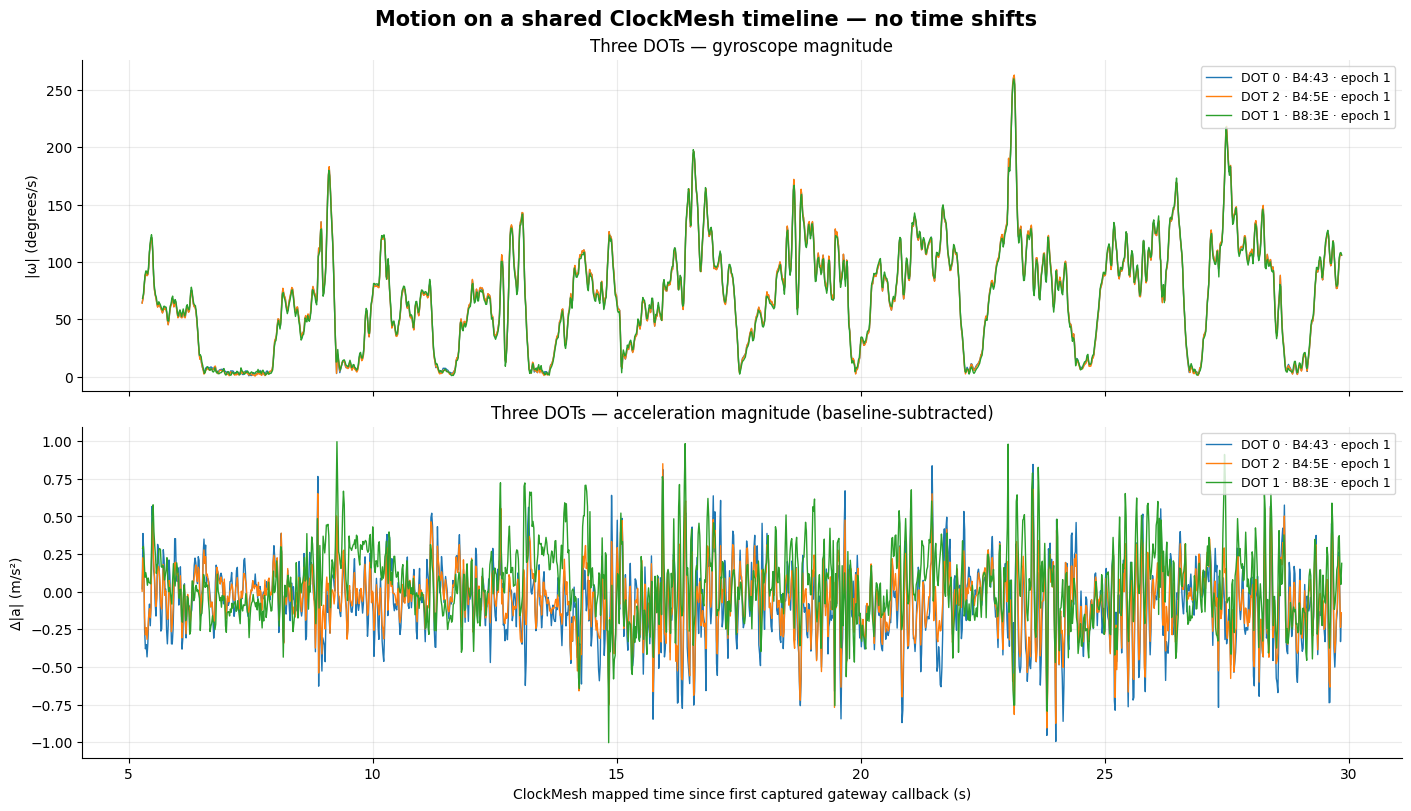

In [12]:
if SHOW_MAGNITUDES:
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, layout="constrained")
    for key in keys:
        data = motion_rows_for(key)
        if not data:
            continue
        t = mapped_seconds(data)
        color = color_for[key]
        label = label_for(key)

        gyro_magnitude = np.linalg.norm(motion_xyz(data, "gyro"), axis=1)
        accel_magnitude = np.linalg.norm(motion_xyz(data, "accel"), axis=1)
        if ACCEL_DISPLAY == "deviation":
            baseline = np.nanmedian(accel_magnitude[:min(120, len(accel_magnitude))])
            accel_magnitude = accel_magnitude - baseline

        axes[0].plot(t, gyro_magnitude, lw=1.0, color=color, label=label)
        axes[1].plot(t, accel_magnitude, lw=1.0, color=color, label=label)

    axes[0].set(title="Three DOTs — gyroscope magnitude",
                ylabel="|ω| (degrees/s)")
    axes[1].set(
        title="Three DOTs — acceleration magnitude" +
              (" (baseline-subtracted)" if ACCEL_DISPLAY == "deviation" else ""),
        ylabel="Δ|a| (m/s²)" if ACCEL_DISPLAY == "deviation" else "|a| (m/s²)",
        xlabel="ClockMesh mapped time since first captured gateway callback (s)"
    )
    set_motion_xlim(axes)
    for axis in axes:
        axis.grid(alpha=.25)
        axis.legend(loc="upper right", fontsize=9)
    fig.suptitle("Motion on a shared ClockMesh timeline — no time shifts",
                 fontsize=15, fontweight="bold")
    finish_figure(fig, "02_motion_magnitudes.png")


## 3 — Full motion channels

The original CLI tool's **ten individual motion channels** (quaternion, accelerometer XYZ and gyroscope XYZ) are split across three readable figures. All use ClockMesh mapped timestamps and the same shared time origin. Different orientations can make individual axes look different even when sensors undergo the same motion.

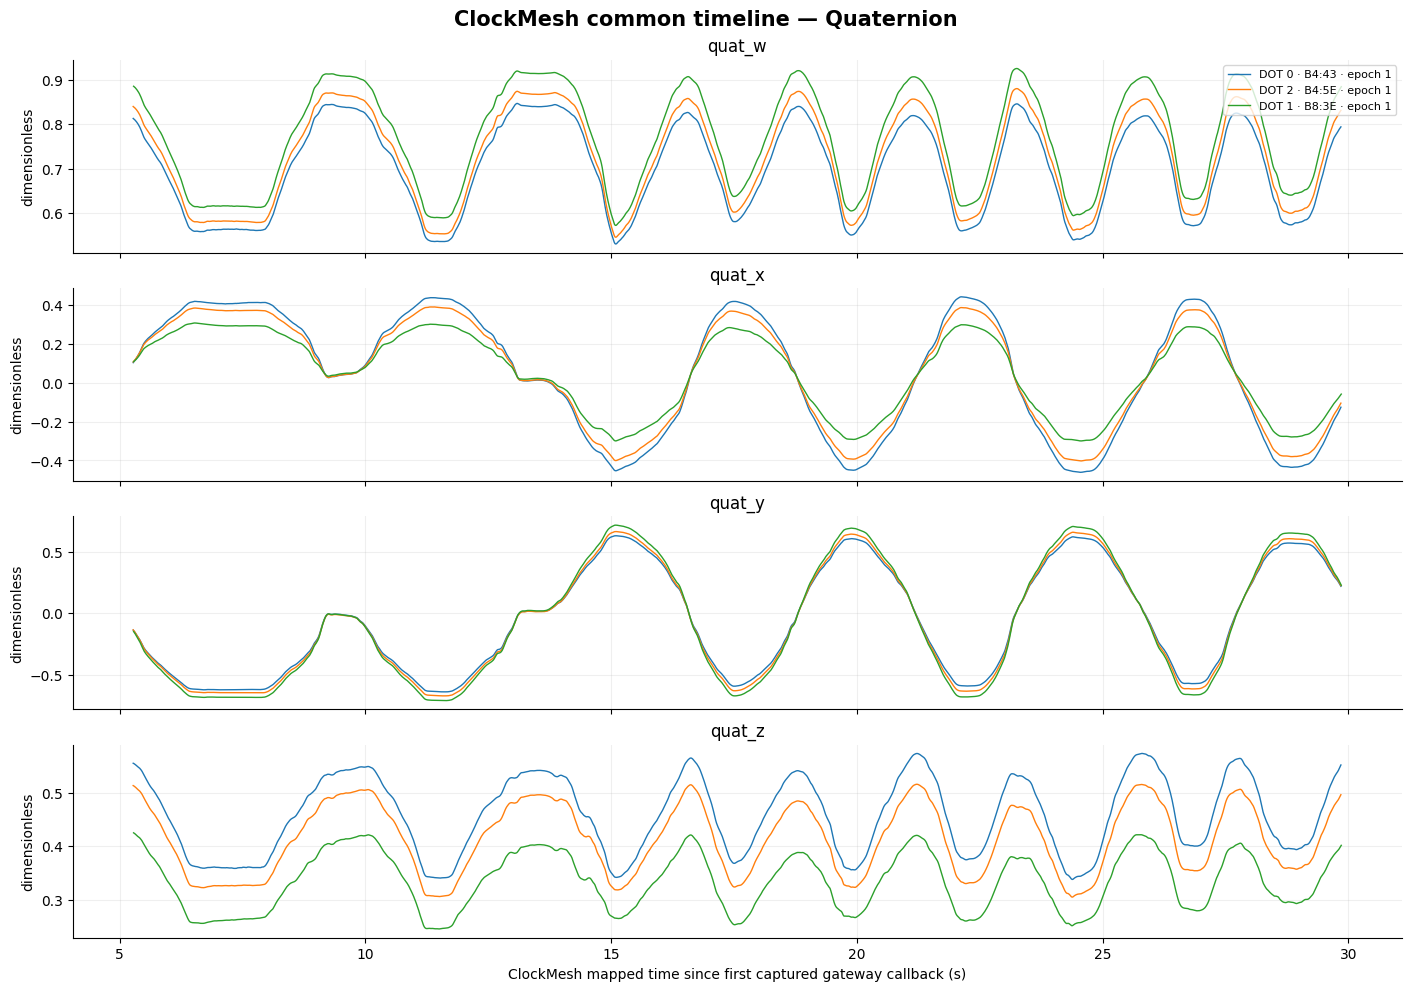

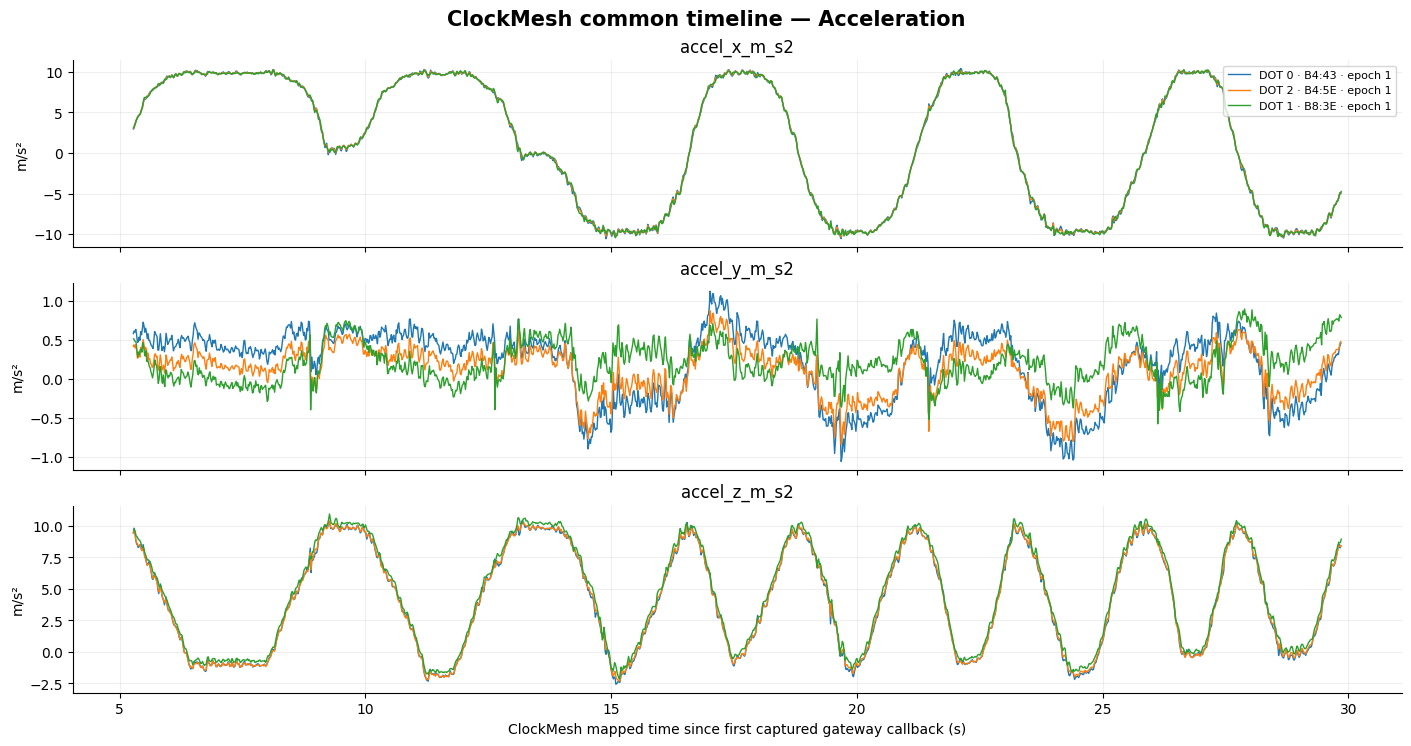

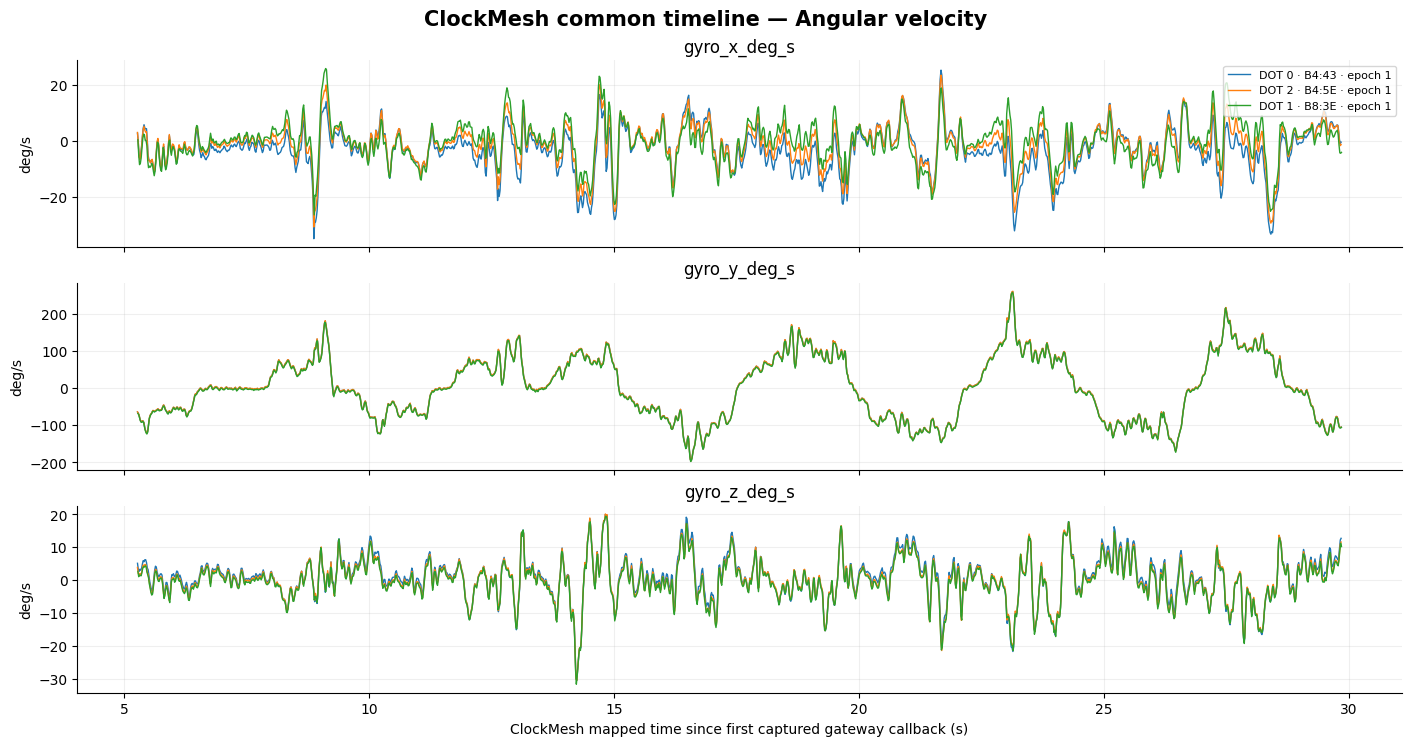

In [13]:
if SHOW_INDIVIDUAL_CHANNELS:
    channel_families = (
        ("Quaternion", "quat_", "03_quaternion_channels.png"),
        ("Acceleration", "accel_", "04_accel_channels.png"),
        ("Angular velocity", "gyro_", "05_gyro_channels.png"),
    )
    for title, prefix, filename in channel_families:
        channels = [(column, unit) for column, _short, unit in MOTION_CHANNELS
                    if column.startswith(prefix) and column in columns]
        if not channels:
            print(f"No {title.lower()} columns found; skipping")
            continue
        fig, axes = plt.subplots(
            len(channels), 1, figsize=(14, 2.45 * len(channels)),
            sharex=True, layout="constrained"
        )
        axes = np.atleast_1d(axes)
        for key in keys:
            data = motion_rows_for(key)
            if not data:
                continue
            t = mapped_seconds(data)
            for axis, (column, unit) in zip(axes, channels):
                axis.plot(t, numeric_column(data, column), color=color_for[key],
                          lw=1.0, label=label_for(key))
        for axis, (column, unit) in zip(axes, channels):
            axis.set(title=column, ylabel=unit)
            axis.grid(alpha=.2)
        axes[0].legend(loc="upper right", fontsize=8)
        axes[-1].set_xlabel("ClockMesh mapped time since first captured gateway callback (s)")
        set_motion_xlim(axes)
        fig.suptitle(f"ClockMesh common timeline — {title}",
                     fontsize=15, fontweight="bold")
        finish_figure(fig, filename)


### Reading the results

The plots deliberately distinguish **when the BLE gateway processed a notification** (diagnostics) from **when ClockMesh maps the sensor's measurement to the gateway timeline** (motion). The reported 30 ms BLE interval and its deferrals can affect gateway callback residuals; downstream gateway-to-host transport is after the gateway timestamp capture boundary.

For a physical alignment check, mount the three DOTs rigidly, generate several short movement events **after official start**, set `MOTION_ZOOM` around the event and inspect whether the peaks in the overlaid gyro/acceleration magnitudes coincide. The plot itself does not automatically measure or correct pairwise offsets.